# GWAD Delta Similarity Analysis

This notebook looks inside GWAD while it watches an attack. It reads the files that
`demo.py --save_dir` writes to `results/<run>/` and draws three kinds of pictures:

1. **DS histograms**: which DS values an attack produces, compared with normal (benign) queries.
2. **Time series**: how DS changes query by query, and when GWAD first raises the alarm.
3. **DS fingerprints (HoDS)**: the exact input GWAD's classifier (Delta-Net) sees when it decides "attack or not".

### Key ideas in one minute

- A black-box attack sends many slightly changed images (queries) to the model.
  The change from one query to the next is an **update**.
- **DS (delta similarity)** compares two updates in a row: take three queries `x0, x1, x2`,
  then DS = cosine of the angle between `x1 - x0` and `x2 - x1`.
  - **DS near +1**: the attack keeps moving in the same direction.
  - **DS near -1**: the attack steps back along the same line (it reverses).
  - **DS near 0**: the two updates are unrelated. This is typical for normal users.
- **HoDS (histogram of DS)**: GWAD keeps the last 256 DS values and counts them in 201 bins
  (each bin is 0.01 wide). This histogram is the attack's "fingerprint". Delta-Net reads it and
  names the attack, or says `benign`.
- **Screener (GWAD+ only)**: a filter in front of GWAD. It drops queries that look unrelated to
  recent ones, to remove fake "dummy" queries an attacker mixes in. In the timeline,
  `screened = 1` means the query was dropped and GWAD never saw it.

One caveat: the timeline stores DS with only 6 decimals, so a rebuilt HoDS could in theory land one
bin off. Section 4 checks this by re-running Delta-Net and comparing with the saved predictions.

In [1]:
import csv
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Find the project root (the folder with gwad.py), so the notebook works from any subfolder.
ROOT = Path.cwd().resolve()
while not (ROOT / 'gwad.py').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Project root (the folder with gwad.py) not found')
    ROOT = ROOT.parent

# Same values as in gwad.py
DS_SIZE = 256      # number of recent DS values in one HoDS (gwad.py: ds_size)
HODS_BINS = 200    # HoDS has 200 + 1 = 201 bins (gwad.py: hods_bins)
CLASSES = ['benign', 'hsja', 'nes', 'simba', 'sign-opt', 'sign-flip', 'ba']   # Delta-Net outputs
COLORS = dict(zip(CLASSES, ['#2a9d8f', '#e76f51', '#f4a261', '#8d99ae', '#9b5de5', '#e63946', '#457b9d']))
BIN_CENTERS = -1 + (np.arange(HODS_BINS + 1) + 0.5) * (2 / HODS_BINS)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# All runs saved with --save_dir
runs = sorted(p for p in (ROOT / 'results').iterdir() if (p / 'gwad_timeline.csv').exists())
for i, p in enumerate(runs):
    print(i, p.name)

0 20261015-133012_hsja_standard_resnet18
1 20261015-133428_hsja_batch_resnet18
2 20261015-133803_benign_resnet18
3 20261015-134055_hsja_standard_mobilenet
4 20261114-105906_rays_standard_resnet18
5 20261114-105933_rays_batch_resnet18


## 0. Pick the runs to look at

By default this uses the newest RayS run as the attack, and the newest benign run as the
"normal traffic" reference. To use another run, replace the line with its folder name, e.g.
`ATTACK_RUN = ROOT / 'results' / '20261114-105906_rays_standard_resnet18'`.

In [2]:
ATTACK_RUN = next(p for p in reversed(runs) if '_rays_' in p.name)
BENIGN_RUN = next((p for p in reversed(runs) if '_benign_' in p.name), None)
MAX_IMAGES = 6   # draw time series for at most this many attacked images

print('attack run :', ATTACK_RUN.name)
print('benign run :', BENIGN_RUN.name if BENIGN_RUN else None)

attack run : 20261114-105933_rays_batch_resnet18
benign run : 20261015-133803_benign_resnet18


In [3]:
def load_run(run_dir):
    # Read one run folder.
    # Returns {'name', 'cfg', 'summary': {img: row}, 'images': {img: dict of numpy arrays}}
    with open(run_dir / 'gwad_timeline.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    grouped = {}
    for r in rows:
        grouped.setdefault(int(r['img']), []).append(r)

    images = {}
    for img, rs in grouped.items():
        images[img] = {
            'query': np.array([int(r['query']) for r in rs]),               # query number (dummies included)
            'type': np.array([r['type'] for r in rs]),                      # 'attack' or 'benign' (dummy)
            'screened': np.array([r['screened'] == '1' for r in rs]),       # True = dropped by the Screener
            'ds': np.array([float(r['ds']) if r['ds'] else np.nan for r in rs]),
            'pred': np.array([r['pred'] or None for r in rs], dtype=object),  # Delta-Net output, None = no output yet
        }

    summary = {}
    if (run_dir / 'summary.csv').exists():
        with open(run_dir / 'summary.csv', newline='') as f:
            summary = {int(r['img']): r for r in csv.DictReader(f)}
    cfg_path = run_dir / 'run_config.json'
    cfg = json.loads(cfg_path.read_text(encoding='utf-8')) if cfg_path.exists() else None
    return {'name': run_dir.name, 'cfg': cfg, 'summary': summary, 'images': images}


def ds_seq(im):
    # Only the queries that produced a DS, in order: (query number, ds, prediction, query type)
    m = ~np.isnan(im['ds'])
    return im['query'][m], im['ds'][m], im['pred'][m], im['type'][m]


attack = load_run(ATTACK_RUN)
benign = load_run(BENIGN_RUN) if BENIGN_RUN else None
if attack['cfg']:
    print(json.dumps(attack['cfg']['cfg'], indent=1))

{
 "attack": {
  "name": "rays",
  "query_budget": 10000,
  "adaptive": {
   "name": "batch",
   "move_rate": 1.0,
   "batch_size": 10,
   "pool_size": 2000
  }
 },
 "gwad": {
  "screen": {
   "on": true,
   "n": 100,
   "thold": 0.4
  },
  "model": {
   "name": "resnet18",
   "data_mu": [
    0.4914,
    0.4822,
    0.4465
   ],
   "data_std": [
    0.247,
    0.243,
    0.261
   ],
   "data_format": "tensor"
  }
 }
}


## 1. Summary per image

One row per attacked image:

| column | meaning |
|---|---|
| `success` | 1 if the attack fooled the model |
| `atk q` | number of attack queries |
| `total q` | all queries, including dummy queries |
| `first det` | query number of GWAD's first alarm (`-` = never detected) |
| `verdict` | the attack name GWAD guessed most often |
| `atk passed` / `atk screened` | attack queries the Screener let through / dropped. Dropped queries are invisible to GWAD. |
| `n ds` | how many DS values GWAD computed. Delta-Net needs at least 256 before its first answer. |
| `det rate` | share of Delta-Net answers that were "attack" (not `benign`) |
| `abs(ds)>.9` | share of DS values close to +1 or -1, i.e. updates on almost the same line |

In [4]:
def summarize(run):
    hdr = ['img', 'success', 'atk q', 'total q', 'first det', 'verdict',
           'atk passed', 'atk screened', 'n ds', 'det rate', 'abs(ds)>.9']
    print(run['name'])
    print(('{:>13}' * len(hdr)).format(*hdr))
    for img, im in run['images'].items():
        s = run['summary'].get(img, {})
        atk = im['type'] == 'attack'
        _, ds, pred, _ = ds_seq(im)
        has_pred = np.array([p is not None for p in pred])
        det = np.mean([p != 'benign' for p in pred[has_pred]]) if has_pred.any() else np.nan
        print(('{:>13}' * len(hdr)).format(
            img, s.get('attack_success', ''), s.get('attack_queries', ''), s.get('total_queries', ''),
            s.get('first_detection', '') or '-', s.get('gwad_verdict', ''),
            int((atk & ~im['screened']).sum()), int((atk & im['screened']).sum()), len(ds),
            f'{det:.3f}', f'{np.mean(np.abs(ds) > 0.9):.3f}' if len(ds) else 'nan'))


summarize(attack)
# Also list the other RayS runs, e.g. to compare the standard and batch scenarios
for p in runs:
    if '_rays_' in p.name and p != ATTACK_RUN:
        print()
        summarize(load_run(p))

20261114-105933_rays_batch_resnet18
          img      success        atk q      total q    first det      verdict   atk passed atk screened         n ds     det rate   abs(ds)>.9
         2000            1          427         4697         2926     sign-opt          419            8          417        1.000        0.652
         2001            1          146         1606            -         none          143            3          141          nan        0.745
         2002            1          201         2211            -         none          191           10          189          nan        0.704

20261114-105906_rays_standard_resnet18
          img      success        atk q      total q    first det      verdict   atk passed atk screened         n ds     det rate   abs(ds)>.9
            0            1          687          687          262     sign-opt          683            4          681        1.000        0.648
            1            1         1617         1617        

## 2. DS histograms

**Left:** the DS values of each attacked image (red), drawn over the DS values of normal queries
(gray, rescaled to the same total so the shapes are easy to compare). The y-axis is logarithmic.

**Right:** the same DS values, split by the type of the newest query. This only matters in the
`batch` scenario, where the attacker mixes dummy (benign) queries between attack queries.

What to look for: normal queries spread around the middle, while an attack piles up at +1 and -1.
The more an attack's histogram looks like the gray one, the harder it is for GWAD to spot.

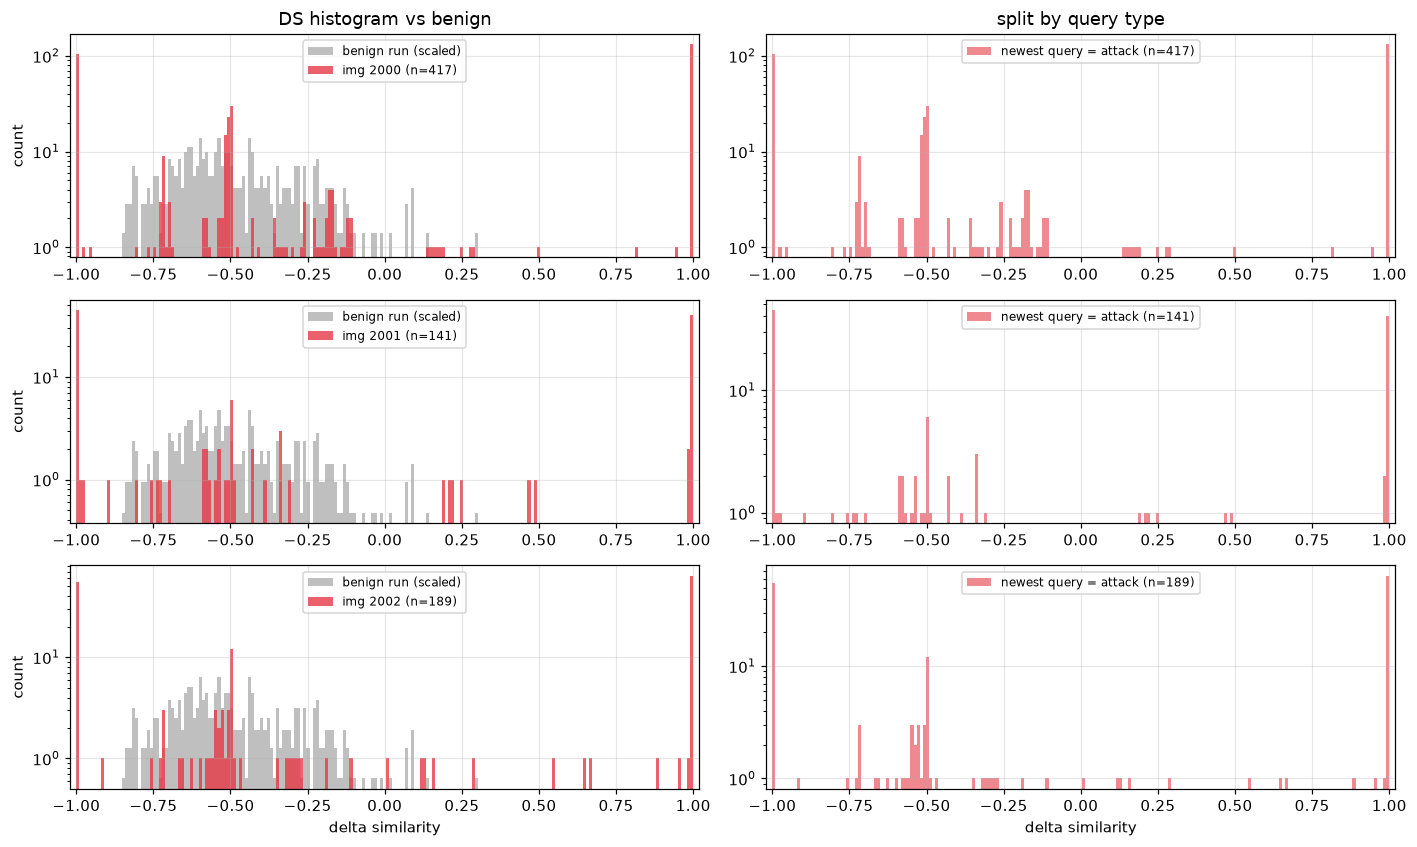

In [5]:
bins = np.linspace(-1, 1, HODS_BINS + 2)
benign_ds = np.concatenate([ds_seq(im)[1] for im in benign['images'].values()]) if benign else np.array([])

imgs = list(attack['images'])[:MAX_IMAGES]
fig, axes = plt.subplots(len(imgs), 2, figsize=(13, 2.6 * len(imgs)), squeeze=False)
for row, img in zip(axes, imgs):
    _, ds, _, typ = ds_seq(attack['images'][img])
    ax = row[0]
    if len(benign_ds):
        w = np.full(len(benign_ds), len(ds) / len(benign_ds))
        ax.hist(benign_ds, bins=bins, weights=w, color='gray', alpha=0.5, label='benign run (scaled)')
    ax.hist(ds, bins=bins, color=COLORS['sign-flip'], alpha=0.8, label=f'img {img} (n={len(ds)})')
    ax.set_yscale('log'); ax.set_xlim(-1.02, 1.02); ax.set_ylabel('count'); ax.legend(fontsize=8)

    ax = row[1]
    for t, c in [('attack', COLORS['sign-flip']), ('benign', COLORS['benign'])]:
        m = typ == t
        if m.any():
            ax.hist(ds[m], bins=bins, color=c, alpha=0.6, label=f'newest query = {t} (n={m.sum()})')
    ax.set_yscale('log'); ax.set_xlim(-1.02, 1.02); ax.legend(fontsize=8)
axes[-1, 0].set_xlabel('delta similarity'); axes[-1, 1].set_xlabel('delta similarity')
axes[0, 0].set_title('DS histogram vs benign'); axes[0, 1].set_title('split by query type')
fig.tight_layout()

### 2b. Average DS histogram of each attack

Each run also saves `stats/hist/<data>_<model>_<attack>.txt`: the DS histogram averaged over all
attacked images, with 2001 fine bins. Here they are merged into 201 bins so the shapes of different
attacks can be compared on one plot.

Note: each new run of the same attack overwrites its file, so every line shows the **latest** run
of that attack (standard or batch, whichever ran last).

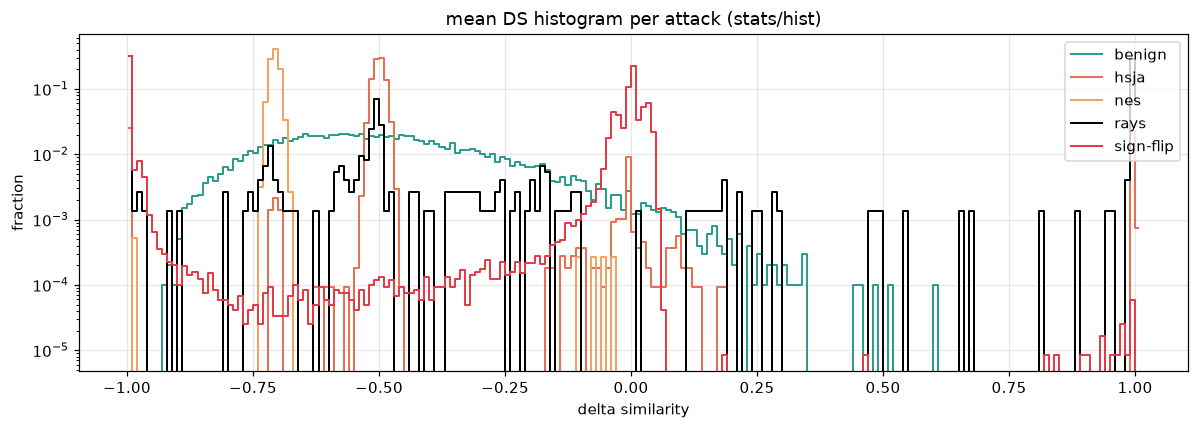

In [6]:
hist_dir = ROOT / 'stats' / 'hist'
fig, ax = plt.subplots(figsize=(11, 4))
for f in sorted(hist_dir.glob('*.txt')):
    h = np.loadtxt(f)
    if h.sum() == 0:
        continue
    coarse = np.add.reduceat(h[:-1], np.arange(0, len(h) - 1, 10))   # merge 2000 bins into 200
    coarse = np.append(coarse, h[-1])                                 # keep the last bin (DS = +1)
    name = f.stem.split('_')[-1]
    ax.step(BIN_CENTERS, coarse / coarse.sum(), where='mid', label=name,
            color=COLORS.get(name, 'black'), lw=1.3)
ax.set_yscale('log'); ax.set_xlabel('delta similarity'); ax.set_ylabel('fraction')
ax.set_title('mean DS histogram per attack (stats/hist)'); ax.legend()
fig.tight_layout()

## 3. Time series

One figure per attacked image. The x-axis is the query number (dummy queries included).

**Top panel:** every DS value as a dot, colored by Delta-Net's answer at that moment.
- Gray dots: fewer than 256 DS values so far, so Delta-Net has not answered yet.
- Red ticks at the bottom: attack queries the Screener dropped.

**Bottom panel:** among the last 256 DS values, the share that is close to +1 (`DS > 0.9`),
close to -1 (`DS < -0.9`), or close to 0 (`|DS| < 0.1`).

**Vertical lines:** dashed = GWAD's first detection; solid = the attack ended.

What to look for: if the solid line comes before the dashed line (or there is no dashed line),
the attack finished before GWAD noticed it.

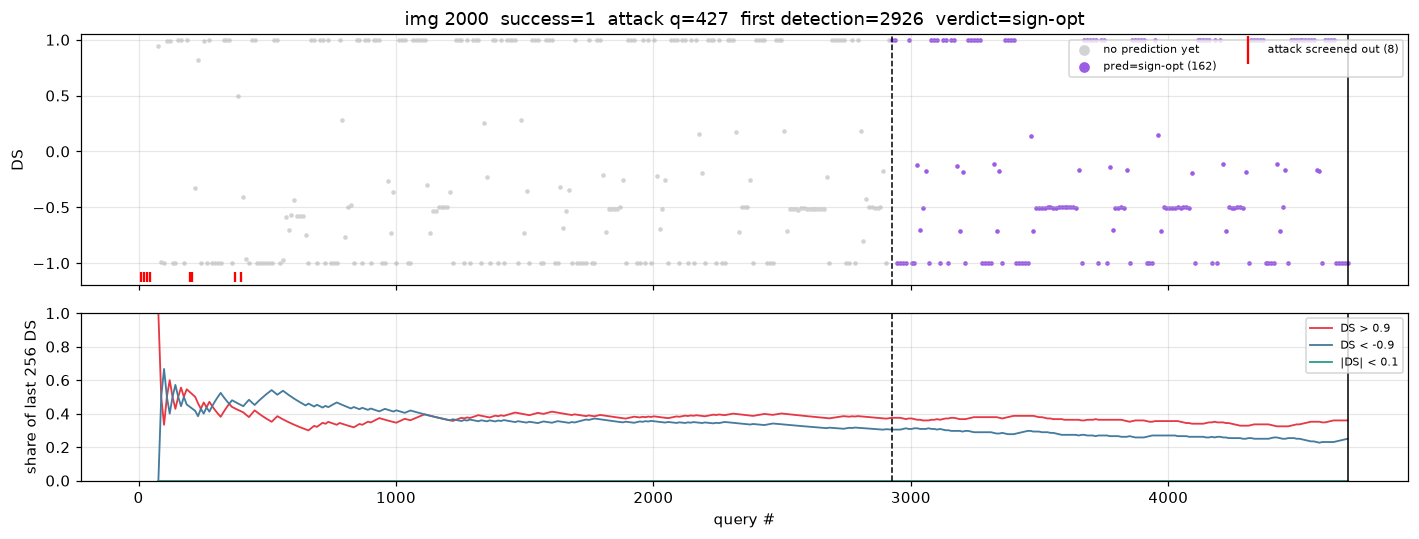

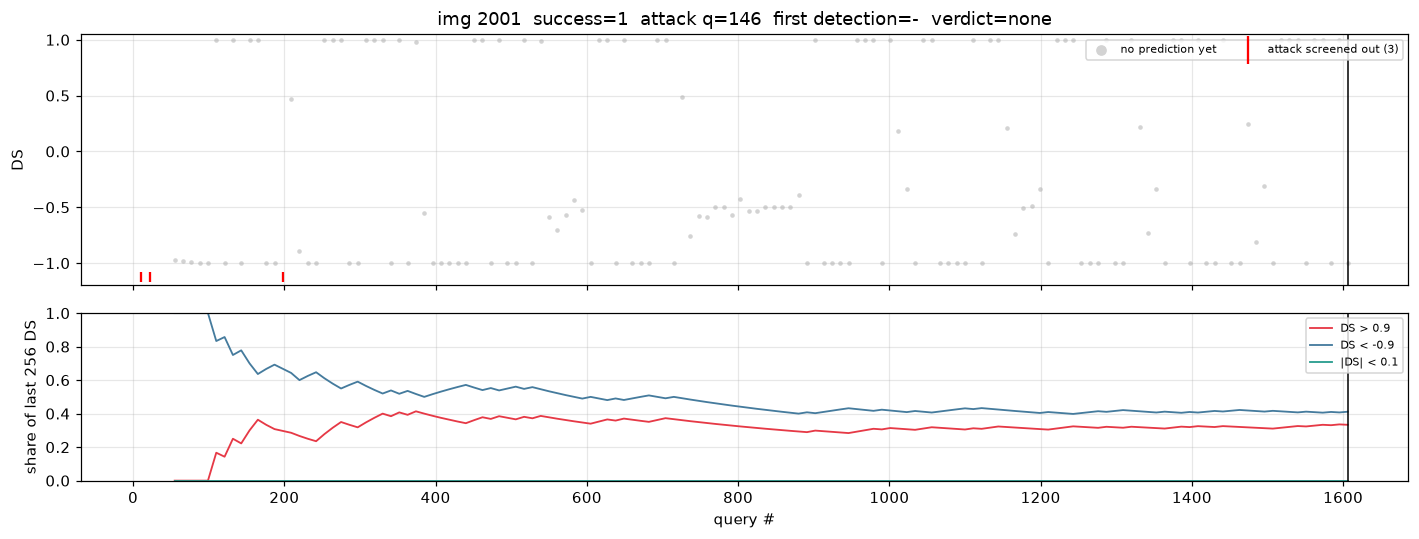

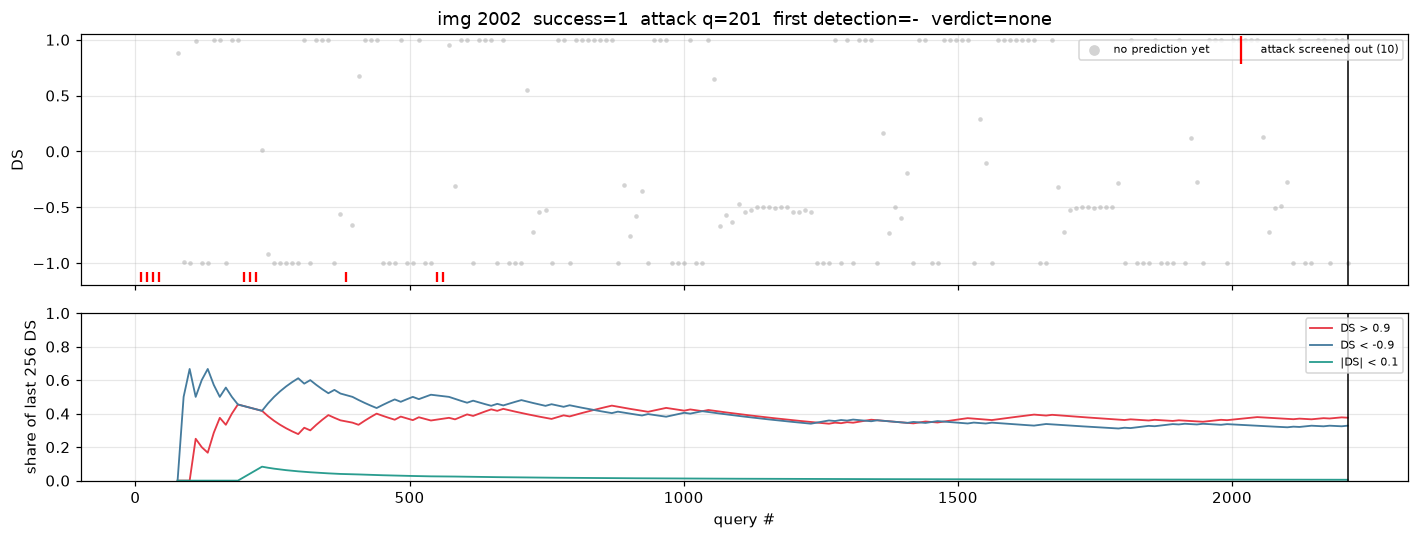

In [7]:
def rolling_frac(mask, w=DS_SIZE):
    # share of True values among the last w entries, at every position
    c = np.cumsum(np.insert(mask.astype(float), 0, 0))
    n = np.minimum(np.arange(1, len(mask) + 1), w)
    return (c[1:] - c[np.maximum(np.arange(1, len(mask) + 1) - w, 0)]) / n


for img in list(attack['images'])[:MAX_IMAGES]:
    im = attack['images'][img]
    s = attack['summary'].get(img, {})
    q, ds, pred, _ = ds_seq(im)
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(13, 5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

    none = np.array([p is None for p in pred])
    a0.scatter(q[none], ds[none], s=4, c='lightgray', label='no prediction yet')
    for cls in CLASSES:
        m = pred == cls
        if m.any():
            a0.scatter(q[m], ds[m], s=4, c=COLORS[cls], label=f'pred={cls} ({m.sum()})')
    scr = (im['type'] == 'attack') & im['screened']
    a0.scatter(im['query'][scr], np.full(scr.sum(), -1.12), marker='|', c='red', s=40,
               label=f'attack screened out ({scr.sum()})')
    a0.set_ylim(-1.2, 1.05); a0.set_ylabel('DS')
    a0.legend(fontsize=7, loc='upper right', markerscale=3, ncol=2)

    for name, m, c in [('DS > 0.9', ds > 0.9, '#e63946'), ('DS < -0.9', ds < -0.9, '#457b9d'),
                       ('|DS| < 0.1', np.abs(ds) < 0.1, '#2a9d8f')]:
        a1.plot(q, rolling_frac(m), label=name, color=c, lw=1.2)
    a1.set_ylim(0, 1); a1.set_ylabel(f'share of last {DS_SIZE} DS'); a1.set_xlabel('query #')
    a1.legend(fontsize=7, loc='upper right')

    for a in (a0, a1):
        if s.get('first_detection'):
            a.axvline(int(s['first_detection']), color='k', ls='--', lw=1)
        if s.get('total_queries'):
            a.axvline(int(s['total_queries']), color='k', lw=1)
    a0.set_title(f"img {img}  success={s.get('attack_success')}  attack q={s.get('attack_queries')}  "
                 f"first detection={s.get('first_detection') or '-'}  verdict={s.get('gwad_verdict')}")
    fig.tight_layout()

## 4. DS fingerprints (HoDS)

Here we rebuild exactly what Delta-Net sees, the same way `gwad.py` does:

1. Take the last 256 DS values.
2. Count them in 201 bins of width 0.01 (one HoDS).
3. Scale the counts to the range 0 to 1 (min-max) and feed them to Delta-Net.

Every new DS value shifts the window by one, so each image gives a sequence of HoDS.
The cell below also loads Delta-Net, predicts again from the rebuilt HoDS, and prints how often the
new predictions match the ones saved during the run. 1.0000 means the rebuild is exact.

In [8]:
import torch

sys.path.insert(0, str(ROOT))
from net.delta.ann_hist.ann_hist import ANN_HIST

delta_net = ANN_HIST(len_op=len(CLASSES))
delta_net.load_state_dict(torch.load(ROOT / 'model' / 'delta' / 'delta_ann.pt', map_location='cpu'))
delta_net.eval()


def hods_bins(ds):
    # bin index of each DS value, same float32 math as gwad._hods_bin
    return (np.abs(np.float32(-1) - ds.astype(np.float32)) // np.float32(2 / HODS_BINS)).astype(int)


def hods_series(ds):
    # All HoDS of one image, as raw counts: shape (len(ds) - 255, 201).
    # Row i is the HoDS right after DS number i + 255 (0-based).
    b = hods_bins(ds)
    if len(b) < DS_SIZE:
        return np.zeros((0, HODS_BINS + 1), np.float32)
    H = np.empty((len(b) - DS_SIZE + 1, HODS_BINS + 1), np.float32)
    h = np.bincount(b[:DS_SIZE], minlength=HODS_BINS + 1).astype(np.float32)
    H[0] = h
    for k in range(DS_SIZE, len(b)):
        h[b[k - DS_SIZE]] -= 1   # oldest DS leaves the window
        h[b[k]] += 1             # newest DS enters
        H[k - DS_SIZE + 1] = h
    return H


def normalize(H):
    # min-max scaling of each HoDS, as done before Delta-Net
    m0 = H.min(axis=1, keepdims=True); m1 = H.max(axis=1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.nan_to_num((H - m0) / (m1 - m0))


@torch.no_grad()
def delta_probs(H):
    # Delta-Net's probability for each class, one row per HoDS
    if len(H) == 0:
        return np.zeros((0, len(CLASSES)))
    return delta_net(torch.from_numpy(normalize(H))).exp().numpy()


def fingerprints(run):
    # For each image: HoDS sequence, matching query numbers, saved predictions, new probabilities
    out = {}
    for img, im in run['images'].items():
        q, ds, pred, _ = ds_seq(im)
        H = hods_series(ds)
        out[img] = {'H': H, 'q': q[DS_SIZE - 1:], 'pred': pred[DS_SIZE - 1:], 'prob': delta_probs(H)}
    return out


fp = fingerprints(attack)
fp_benign = fingerprints(benign) if benign else {}

for name, f in [('attack', fp), ('benign', fp_benign)]:
    rec = np.concatenate([v['pred'] for v in f.values()]) if f else np.array([])
    new = np.concatenate([np.array(CLASSES)[v['prob'].argmax(1)] for v in f.values()]) if f else np.array([])
    if len(rec):
        print(f'{name}: {len(rec)} HoDS, new predictions match the saved ones: {np.mean(rec == new):.4f}')

attack: 162 HoDS, new predictions match the saved ones: 1.0000
benign: 43 HoDS, new predictions match the saved ones: 1.0000


### 4a. How the fingerprint changes over time (one image)

- **Top strip:** Delta-Net's answer at each query (colors as in section 3).
- **Middle heat map:** each column is one HoDS. The y-axis is the DS value, and brighter means
  more DS values in that bin (log scale). Bright rows at the top and bottom mean the attack keeps
  producing DS near +1 and -1.
- **Bottom:** Delta-Net's probability for each class. Only classes that ever go above 5% are drawn.

Change `IMG` to look at another image. Images with fewer than 256 DS values have no HoDS at all.

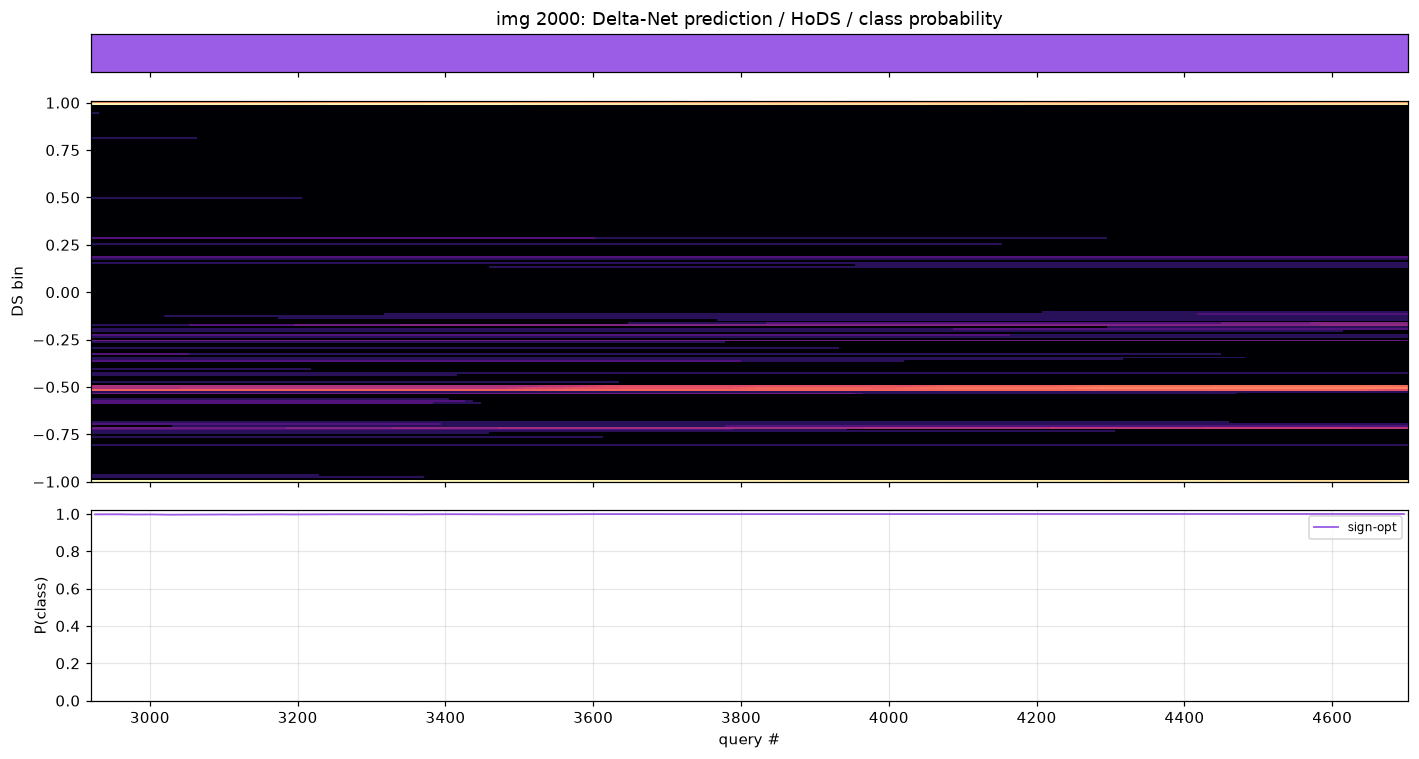

In [9]:
IMG = list(fp)[0]   # change to the image number you want
v = fp[IMG]
if len(v['H']) == 0:
    print(f'img {IMG} has fewer than {DS_SIZE} DS values, so GWAD never built a HoDS for it')
else:
    fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(13, 7), sharex=True,
                                     gridspec_kw={'height_ratios': [0.4, 4, 2]})
    x = v['q']
    cidx = np.array([CLASSES.index(p) for p in v['pred']])
    # pcolormesh places each column at its real query number (in batch runs they are not evenly spaced)
    a0.pcolormesh(x, [0, 1], np.vstack([cidx, cidx]), shading='nearest',
                  cmap=ListedColormap([COLORS[c] for c in CLASSES]), vmin=0, vmax=len(CLASSES) - 1)
    a0.set_yticks([]); a0.grid(False); a0.set_title(f'img {IMG}: Delta-Net prediction / HoDS / class probability')

    a1.pcolormesh(x, BIN_CENTERS, np.log1p(v['H'].T), shading='nearest', cmap='magma')
    a1.set_ylabel('DS bin'); a1.grid(False)

    for k, c in enumerate(CLASSES):
        if v['prob'][:, k].max() > 0.05:
            a2.plot(x, v['prob'][:, k], color=COLORS[c], label=c, lw=1.2)
    a2.set_ylim(0, 1.02); a2.set_ylabel('P(class)'); a2.set_xlabel('query #'); a2.legend(fontsize=8, ncol=4)
    fig.tight_layout()

### 4b. Comparing fingerprints

The gray line in both plots is the average HoDS of normal (benign) queries.

- **Left:** the chosen image's HoDS at GWAD's **first detection** and at the **last query**.
- **Right:** all HoDS of this run, grouped by Delta-Net's answer and averaged. This is what a HoDS
  typically looks like when Delta-Net calls it a given attack.

What to look for: an attack that wants to stay hidden must make its curve look like the gray one,
i.e. move weight away from the spikes at -1 and +1 toward the middle.

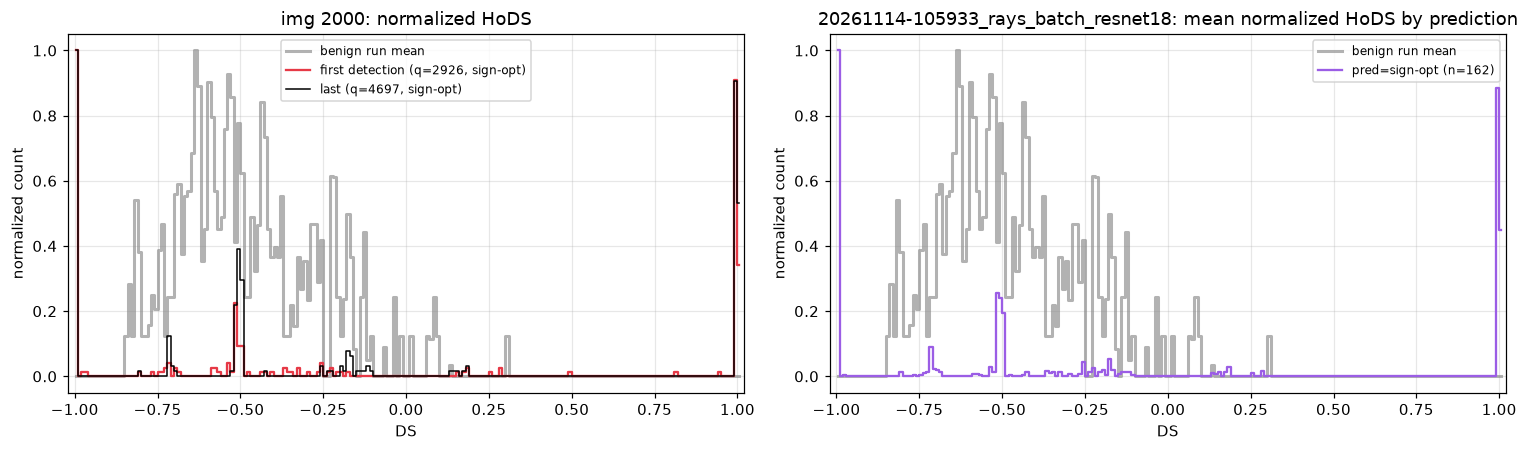

In [10]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))

if fp_benign:
    Hb = np.concatenate([normalize(f['H']) for f in fp_benign.values() if len(f['H'])])
    for a in (a0, a1):
        a.step(BIN_CENTERS, Hb.mean(0), where='mid', color='gray', lw=2, alpha=0.6, label='benign run mean')

v = fp[IMG]
if len(v['H']):
    Hn = normalize(v['H'])
    det = np.flatnonzero(v['pred'] != 'benign')
    if len(det):
        a0.step(BIN_CENTERS, Hn[det[0]], where='mid', color=COLORS['sign-flip'],
                label=f"first detection (q={v['q'][det[0]]}, {v['pred'][det[0]]})")
    a0.step(BIN_CENTERS, Hn[-1], where='mid', color='k', lw=1, label=f"last (q={v['q'][-1]}, {v['pred'][-1]})")
a0.set_title(f'img {IMG}: normalized HoDS'); a0.set_xlabel('DS'); a0.legend(fontsize=8)

allH = [normalize(f['H']) for f in fp.values() if len(f['H'])]
allP = [f['pred'] for f in fp.values() if len(f['H'])]
if allH:
    allH, allP = np.concatenate(allH), np.concatenate(allP)
    for c in CLASSES:
        m = allP == c
        if m.any():
            a1.step(BIN_CENTERS, allH[m].mean(0), where='mid', color=COLORS[c], label=f'pred={c} (n={m.sum()})')
a1.set_title(f"{attack['name']}: mean normalized HoDS by prediction"); a1.set_xlabel('DS'); a1.legend(fontsize=8)
for a in (a0, a1):
    a.set_ylabel('normalized count'); a.set_xlim(-1.02, 1.02)
fig.tight_layout()

### 4c. Which attack does Delta-Net think RayS is?

Delta-Net was never trained on RayS, so it has no `rays` class. This chart shows the average
probability of each class per image. A tall bar tells you which known attack RayS looks most
like. A high `benign` bar means RayS comes close to slipping past GWAD.
The black dashes show the same averages for the benign run, for reference.

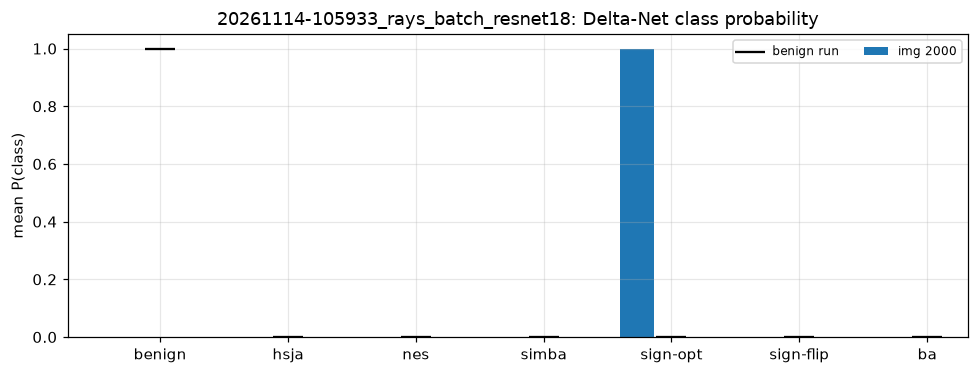

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
width = 0.8 / max(len(fp), 1)
for i, (img, v) in enumerate(fp.items()):
    if len(v['prob']):
        ax.bar(np.arange(len(CLASSES)) + i * width, v['prob'].mean(0), width, label=f'img {img}')
if fp_benign:
    Pb = np.concatenate([v['prob'] for v in fp_benign.values() if len(v['prob'])])
    ax.scatter(np.arange(len(CLASSES)) + 0.4 - width / 2, Pb.mean(0), marker='_', s=400, c='k',
               label='benign run', zorder=3)
ax.set_xticks(np.arange(len(CLASSES)) + 0.4 - width / 2, CLASSES)
ax.set_ylabel('mean P(class)'); ax.set_title(f"{attack['name']}: Delta-Net class probability")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()